# Day4：多局 REINFORCE 训练，观察策略怎样改变

学习者：RedMoon。

上一练习完成了一局采样和一次更新。这次只加一层：**重新开始一局 → 按当前策略采样到终点 → 更新一次 → 再开始下一局**。仍用两路线环境、one-hot 状态和线性策略，没有 baseline、Critic、PPO 或经验回放。

按单元顺序运行，不依赖之前 Notebook 的变量。重点看第 5–8 节的循环、曲线和评估。预计阅读与运行约 15–20 分钟，实际训练在 CPU 上就能完成。

代码和解释来自互动教学。保存的执行结果是本机验证，不代替学习者运行和复述。

## 1. 确定训练配置

`num_episodes` 是训练局数，不是单局动作数。长路线一局两步，短路线一局一步；不管几步，都在终点后更新一次。

`seed` 让一次实验更易复现，只在整次训练开始时设置，不能每一局都重新设置同一个种子。`window` 是画图时统计最近多少局的窗口，不参与梯度计算。

算法仍只依赖 PyTorch；画曲线用本机已有的 matplotlib，没有联网调用。

本机 Windows/Anaconda 中，PyTorch 与绘图库可能加载两套 OpenMP 运行库。第一段代码在导入它们之前，将本进程的 MKL 设置为串行模式以避免冲突，不修改系统环境变量，也不忽略重复运行库的错误。如果已经导入过这些库，先重启内核再运行所有单元。

In [1]:
import os
# 本机兼容设置：必须在导入数值库之前执行，只影响当前进程。
if os.name == "nt":
    os.environ["MKL_THREADING_LAYER"] = "SEQUENTIAL"

import math
import torch
from torch import nn
from torch.distributions import Categorical
import matplotlib.pyplot as plt

gamma = 0.9
learning_rate = 0.1
num_episodes = 1000
seed = 1
window = 100
eval_episodes = 500

print("PyTorch：", torch.__version__)
print("训练局数：", num_episodes, "，学习率：", learning_rate)

PyTorch： 2.10.0+cu128
训练局数： 1000 ，学习率： 0.1


## 2. 同一个环境，不换新任务

```text
长路线：状态0 --动作0，奖励0--> 状态1 --任意动作，奖励2--> 终点
短路线：状态0 --动作1，奖励1----------------------------> 终点
```

折扣因子为 `0.9` 时，长路线的起点回报是 `1.8`，短路线是 `1.0`。二者都能结束任务，因此应统计**长路线选择率**，不能把到达终点的比例当成学会更优路线的证据。

In [2]:
class TinyChainEnv:
    def __init__(self):
        self.n_states = 2
        self.n_actions = 2
        self.current_state = 0

    def reset(self):
        self.current_state = 0
        return self.current_state

    def step(self, action):
        if action not in (0, 1):
            raise ValueError("action 必须是 0 或 1")
        if self.current_state == 0:
            if action == 0:
                next_state, reward, terminated = 1, 0.0, False
            else:
                next_state, reward, terminated = None, 1.0, True
        elif self.current_state == 1:
            next_state, reward, terminated = None, 2.0, True
        else:
            raise RuntimeError("回合已结束，请先 reset()")
        self.current_state = next_state
        return next_state, reward, terminated, {}


env = TinyChainEnv()

## 3. 策略从两个动作各 0.5 开始

状态 0 对应 `[[1, 0]]`，状态 1 对应 `[[0, 1]]`。无偏置线性层把状态变成两个 logits，`Categorical` 再给出动作概率。

初始化为 0 是为观察学习起点，不是把最佳策略写进网络。`get_action_probs()` 只查看当前策略，因此使用 `no_grad()`；训练采样函数不关闭梯度。

In [3]:
def state_to_tensor(state, n_states):
    state_tensor = torch.zeros((1, n_states), dtype=torch.float32)
    state_tensor[0, state] = 1.0
    return state_tensor


def get_action_probs(policy, state, n_states):
    with torch.no_grad():
        logits = policy(state_to_tensor(state, n_states))
        return Categorical(logits=logits).probs.squeeze(0)


policy = nn.Linear(env.n_states, env.n_actions, bias=False)
nn.init.zeros_(policy.weight)
optimizer = torch.optim.SGD(policy.parameters(), lr=learning_rate)
initial_weights = policy.weight.detach().clone()
initial_probs = get_action_probs(policy, 0, env.n_states)
print("训练前起点概率：", initial_probs.tolist())

训练前起点概率： [0.5, 0.5]


## 4. 将已经学过的单局采样与回报计算封装起来

函数的作用是避免在多局循环里反复粘贴相同代码，不是新增算法。

`collect_episode()` 每次先 `reset()`，并创建新的 `log_probs`、`rewards`、`trajectory`。这些训练张量只用于本局更新，不放进长期日志；日志只保存普通数字，避免把旧计算图一直留在内存中。

`calculate_returns()` 从真正终止处开始倒序计算，再恢复时间顺序。未结束时先推进 `state`，不能只在起点执行一次动作就返回。

In [4]:
def collect_episode(policy, env):
    state = env.reset()
    log_probs, rewards, trajectory = [], [], []
    while True:
        logits = policy(state_to_tensor(state, env.n_states))
        distribution = Categorical(logits=logits)
        action_tensor = distribution.sample()
        action = int(action_tensor.item())
        log_prob = distribution.log_prob(action_tensor).squeeze(0)
        next_state, reward, terminated, _ = env.step(action)
        log_probs.append(log_prob)  # 张量保留到策略参数的计算图。
        rewards.append(reward)
        trajectory.append((state, action, reward, next_state, terminated))
        if terminated:
            break
        state = next_state
    return log_probs, rewards, trajectory


def calculate_returns(rewards, gamma):
    G = 0.0
    returns = []
    for reward in reversed(rewards):
        G = reward + gamma * G
        returns.append(G)
    returns.reverse()
    return returns

## 5. 多局循环：每局重新采样，终点后更新一次

损失沿用上一练习，与从起点折扣的整局回报目标对应：

$$
L=-\sum_t\gamma^tG_t\log\pi_\theta(a_t\mid s_t)
$$

每局的参数更新后，下一局使用新策略重新采样；不重复使用上一局的 `log_prob` 计算图，不加 `retain_graph=True`。

日志变量：

| 名称 | 意义 |
|---|---|
| `long_probs` | 每次更新后，当前策略在起点选择动作 0 的概率；首项是训练前概率 |
| `sample_returns` | 各训练局实际采样到的起点折扣回报，只能是 1.0 或 1.8 |
| `expected_returns` | 由环境已知两条路线回报精确算出的当前策略期望，不参与训练 |
| `losses` | 各局用于反向传播的损失数值，不是策略表现分数 |
| `grad_norms` | 各局参数梯度的范数，用于检查有限数值 |
| `first_episodes` | 前五局的轨迹与更新前后概率，用来理解波动 |

若当前长路线概率为 $p$，已知环境中精确的起点期望回报为：

$$
J=1.8p+1.0(1-p)=1+0.8p
$$

这是教学环境给我们的核对工具，策略训练仍只使用自己采样到的轨迹。一般未知环境不能直接凭空写出这个精确期望。

In [5]:
def train(policy, env, optimizer, num_episodes, gamma, seed):
    torch.manual_seed(seed)  # 只在整次训练开始设置，不在每局重复设置。
    policy.train()
    p = get_action_probs(policy, 0, env.n_states)[0].item()
    history = {
        "long_probs": [p], "expected_returns": [1 + (2 * gamma - 1) * p],
        "sample_returns": [], "losses": [], "grad_norms": [],
        "first_episodes": [], "step_counts": [], "ended_count": 0,
        "graph_count": 0,
    }

    for episode in range(num_episodes):
        p_before = history["long_probs"][-1]
        log_probs, rewards, trajectory = collect_episode(policy, env)
        returns = calculate_returns(rewards, gamma)
        returns_tensor = torch.tensor(returns, dtype=torch.float32)
        time_steps = torch.arange(len(returns), dtype=torch.float32)
        weights = (gamma ** time_steps) * returns_tensor
        policy_loss = -(torch.stack(log_probs) * weights).sum()

        optimizer.zero_grad()
        policy_loss.backward()
        grad_norm = policy.weight.grad.norm().item()
        optimizer.step()

        # 下面只记普通数字，不保存用于训练的张量或计算图。
        p_after = get_action_probs(policy, 0, env.n_states)[0].item()
        history["long_probs"].append(p_after)
        history["expected_returns"].append(1 + (2 * gamma - 1) * p_after)
        history["sample_returns"].append(returns[0])
        history["losses"].append(policy_loss.item())
        history["grad_norms"].append(grad_norm)
        history["step_counts"].append(len(trajectory))
        history["ended_count"] += int(trajectory[-1][4])
        history["graph_count"] += int(all(x.requires_grad for x in log_probs))
        if episode < 5:
            history["first_episodes"].append({
                "episode": episode + 1, "trajectory": trajectory,
                "G0": returns[0], "p_before": p_before, "p_after": p_after,
            })
    return history


# 在这里执行一次完整训练。重新实验时，从前面的初始化单元开始运行。
history = train(policy, env, optimizer, num_episodes, gamma, seed)
final_p = history["long_probs"][-1]
print(f"长路线概率：{history['long_probs'][0]:.4f} -> {final_p:.4f}")
print(f"精确期望回报：{history['expected_returns'][0]:.4f} -> "
      f"{history['expected_returns'][-1]:.4f}")
print("最近 100 个训练局的实际平均回报：",
      round(sum(history["sample_returns"][-100:]) / 100, 4))

长路线概率：0.5000 -> 0.9945
精确期望回报：1.4000 -> 1.7956
最近 100 个训练局的实际平均回报： 1.784


## 6. 为何训练中的概率会偶尔下降

无 baseline 时，长路线样本的起点权重为正的 1.8，会提高长路线动作概率；短路线样本的权重为正的 1.0，也会提高短路线动作概率。

因此一次短路线经历可能使长路线概率下降。这是单次采样梯度的波动，不是要求所有更新都增加概率。多次采样的平均梯度提供比较长期期望的信号；实际有限训练的曲线不保证每次都上升。

中间状态两个动作的回报一样，不需要把其中任何一个训练成唯一正确动作。重点观察起点的路线选择。下面直接展示前五局，不额外出算数题。

In [6]:
for row in history["first_episodes"]:
    route = "长路线" if len(row["trajectory"]) == 2 else "短路线"
    print(f"第 {row['episode']} 局，{route}，G0={row['G0']:.1f}："
          f"长路线概率 {row['p_before']:.4f} -> {row['p_after']:.4f}")
    print("  完整轨迹：", row["trajectory"])

downward_updates = sum(
    new < old for old, new in zip(history["long_probs"], history["long_probs"][1:])
)
print("这次训练中，长路线概率下降的更新次数：", downward_updates)

第 1 局，长路线，G0=1.8：长路线概率 0.5000 -> 0.5449
  完整轨迹： [(0, 0, 0.0, 1, False), (1, 1, 2.0, None, True)]
第 2 局，短路线，G0=1.0：长路线概率 0.5449 -> 0.5177
  完整轨迹： [(0, 1, 1.0, None, True)]
第 3 局，长路线，G0=1.8：长路线概率 0.5177 -> 0.5609
  完整轨迹： [(0, 0, 0.0, 1, False), (1, 1, 2.0, None, True)]
第 4 局，短路线，G0=1.0：长路线概率 0.5609 -> 0.5331
  完整轨迹： [(0, 1, 1.0, None, True)]
第 5 局，短路线，G0=1.0：长路线概率 0.5331 -> 0.5065
  完整轨迹： [(0, 1, 1.0, None, True)]
这次训练中，长路线概率下降的更新次数： 27


## 7. 看趋势，不把平滑曲线当训练目标

左图是当前策略的长路线概率。右图同时显示：每局实际采样回报、最近 100 局的平均回报、每次更新后策略的精确期望回报。

最近窗口中的数据来自这 100 局各自的策略，不是固定某一个策略的独立测试结果；下一节才冻结策略做评估。前 100 局不足完整窗口时，用已有局数作分母。

绘图不参与损失或参数更新。图中英文标签用于避免本机字体缺失导致中文方框，知识解释保留中文。

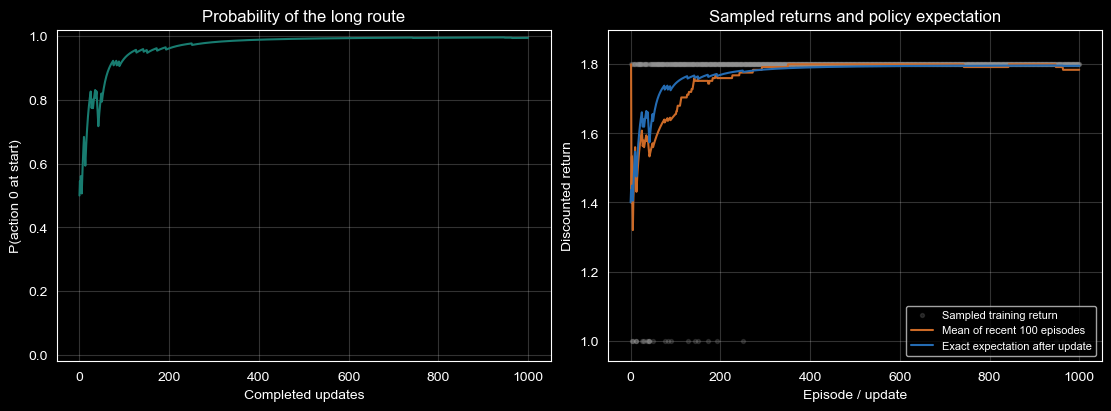

In [7]:
sample_returns = history["sample_returns"]
moving_returns = []
for i in range(len(sample_returns)):
    recent = sample_returns[max(0, i + 1 - window):i + 1]
    moving_returns.append(sum(recent) / len(recent))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].plot(range(num_episodes + 1), history["long_probs"], color="#187c70")
axes[0].set(title="Probability of the long route", xlabel="Completed updates",
            ylabel="P(action 0 at start)", ylim=(-0.02, 1.02))
axes[1].scatter(range(1, num_episodes + 1), sample_returns, s=8,
                color="#999999", alpha=0.2, label="Sampled training return")
axes[1].plot(range(1, num_episodes + 1), moving_returns, color="#cc6a27",
             label=f"Mean of recent {window} episodes")
axes[1].plot(range(num_episodes + 1), history["expected_returns"], color="#246bb2",
             label="Exact expectation after update")
axes[1].set(title="Sampled returns and policy expectation", xlabel="Episode / update",
            ylabel="Discounted return", ylim=(0.94, 1.9))
axes[1].legend(loc="lower right", fontsize=8)
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()

## 8. 冻结策略：采样评估与贪心演示分开

评估中不调用 `backward()` 或 `optimizer.step()`，整个采样过程放在 `no_grad()` 下。

- **采样评估**：仍按训练后策略的概率抽动作。跑 500 局，估计长路线选择率和平均折扣回报；即使环境确定，策略采样也会造成随机性。
- **贪心演示**：每次选概率最大的动作，展示一条完整路线。确定环境和固定贪心策略下重复路线没有新增信息，因此只跑一次。

两条路线都能终止，故不把终点到达率作为策略优劣指标。有限采样的长路线比例不需要精确等于网络概率；不同评估种子可以得到不同统计值。

测试均值不是修改策略用的回报，也不是要求优化器把几个动作概率平均化。

In [8]:
@torch.no_grad()
def evaluate_episode(policy, env, gamma, greedy=False):
    state = env.reset()
    rewards, trajectory = [], []
    while True:
        logits = policy(state_to_tensor(state, env.n_states))
        if greedy:
            action = int(logits.argmax(dim=1).item())
        else:
            action = int(Categorical(logits=logits).sample().item())
        next_state, reward, terminated, _ = env.step(action)
        rewards.append(reward)
        trajectory.append((state, action, reward, next_state, terminated))
        if terminated:
            break
        state = next_state
    return calculate_returns(rewards, gamma)[0], trajectory


policy.eval()
weights_before_eval = policy.weight.detach().clone()
eval_env = TinyChainEnv()
torch.manual_seed(2026)  # 只控制评估采样，不重新初始化已训练参数。
eval_returns, eval_lengths = [], []
eval_long_count = 0
eval_ended_count = 0
for _ in range(eval_episodes):
    episode_return, trajectory = evaluate_episode(policy, eval_env, gamma)
    eval_returns.append(episode_return)
    eval_lengths.append(len(trajectory))
    eval_long_count += int(trajectory[0][1] == 0)
    eval_ended_count += int(trajectory[-1][4])

eval_long_rate = eval_long_count / eval_episodes
eval_mean = sum(eval_returns) / eval_episodes
greedy_return, greedy_trajectory = evaluate_episode(policy, eval_env, gamma, greedy=True)
print(f"固定策略起点长路线概率：{final_p:.4%}")
print(f"采样评估长路线：{eval_long_count}/{eval_episodes} = {eval_long_rate:.4%}")
print(f"采样评估平均折扣回报：{eval_mean:.4f}")
print(f"当前策略精确期望回报：{history['expected_returns'][-1]:.4f}")
print("贪心完整轨迹：", greedy_trajectory)
print("贪心折扣回报：", greedy_return)
print("评估前后参数完全相同：", torch.equal(weights_before_eval, policy.weight))

固定策略起点长路线概率：99.4542%
采样评估长路线：496/500 = 99.2000%
采样评估平均折扣回报：1.7936
当前策略精确期望回报：1.7956
贪心完整轨迹： [(0, 0, 0.0, 1, False), (1, 1, 2.0, None, True)]
贪心折扣回报： 1.8
评估前后参数完全相同： True


## 9. 检查循环和评估，不额外设置算数题

自动检查针对这组默认参数的运行结果：每局终止、每局构造新图、参数有变化、概率合法、默认实验有所改善，以及评估不修改参数。

不要求曲线单调，也不要求长路线概率严格等于 1。若自行改动局数、学习率或折扣因子，训练效果相关的断言可能不再成立；特别是 $\gamma<0.5$ 时长路线不再更优。本节的改善检查不是适用于任意超参数的收敛定理。

In [9]:
checks = 0
assert torch.allclose(initial_probs, torch.tensor([0.5, 0.5]))
checks += 1
assert len(history["sample_returns"]) == num_episodes
checks += 1
assert len(history["long_probs"]) == len(history["expected_returns"]) == num_episodes + 1
checks += 1
assert history["ended_count"] == num_episodes
checks += 1
assert all(n in (1, 2) for n in history["step_counts"])
checks += 1
assert history["graph_count"] == num_episodes
checks += 1
assert all(math.isfinite(x) for name in ("long_probs", "expected_returns", "losses", "grad_norms")
           for x in history[name])
checks += 1
assert final_p > initial_probs[0].item()
checks += 1
assert max(history["grad_norms"]) > 0
checks += 1
assert not torch.equal(initial_weights, policy.weight)
checks += 1
final_probs = get_action_probs(policy, 0, env.n_states)
assert torch.all(final_probs >= 0).item() and torch.isclose(final_probs.sum(), torch.tensor(1.0))
checks += 1
assert math.isclose(history["expected_returns"][-1], 1 + (2 * gamma - 1) * final_p)
checks += 1
assert history["expected_returns"][-1] > history["expected_returns"][0]
checks += 1
assert torch.equal(weights_before_eval, policy.weight)
checks += 1
assert len(eval_returns) == len(eval_lengths) == eval_ended_count == eval_episodes
checks += 1
assert math.isclose(eval_mean, 1 + (2 * gamma - 1) * eval_long_rate)
checks += 1
assert (len(greedy_trajectory) == 2 and greedy_trajectory[0][1] == 0
        and greedy_trajectory[1][0] == 1 and greedy_trajectory[-1][4])
checks += 1
assert math.isclose(greedy_return, 2 * gamma)
checks += 1
assert checks == 18
print(f"通过 {checks} 项检查：完整多局训练、合理概率与冻结策略评估。")

通过 18 项检查：完整多局训练、合理概率与冻结策略评估。


## 10. 这一步与上一练习的关系

单回合练习是看清一次经验怎样改参数；这次多局练习是看清反复采样与更新怎样改善策略。关键变化是循环，不是换了损失公式。

要区分三种量：本局实际得到的回报、当前策略的期望回报、用于计算梯度的策略损失。它们不是同一指标；不要只看到 loss 降低就认定策略一定更好。

所有数据来自当前代码运行。随机种子决定一条具体训练轨迹，单次实跑结果不代表所有种子都会同样变化。后续讨论 baseline 如何改变样本的相对学习信号时，再以本次观察到的波动为起点。